In [27]:
# importing necessary libraries

# ignore warnings
import warnings
warnings.filterwarnings("ignore")

# basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
# sklearn libraries: model selection, preprocessing, pipeline, metrics, classifiers
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# set random state for reproducibility
RANDOM_STATE = 42
print("Setup complete")

Setup complete


# 1. Inspect data & choose features

In [28]:
# load dataframe
df = pd.read_csv('student_learning.csv')

In [29]:
# show the rows and columns of the dataframe
print("Rows, columns:", df.shape)

Rows, columns: (280, 7)


In [30]:
# display the first 5 rows of the dataframe
df.head(5)

,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
0,7.5,54,0,5.6,video,48,0
1,4.4,61,0,6.0,video,50,0
2,8.2,63,1,5.2,group,73,1
3,6.8,64,1,8.4,self,53,0
4,1.3,79,5,5.8,self,51,0


In [31]:
print("Data type:", df.dtypes)

Data type: hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method          str
final_score         int64
passed              int64
dtype: object


In [32]:
print(f"Missing values in each columns:\n{df.isnull().sum()}")

Missing values in each columns:
hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64


In [33]:
print(f"Duplicated rows: {df.duplicated().sum()}")

Duplicated rows: 0


In [34]:
print("Target balance (counts):"); print(df["passed"].value_counts())
print("\nTarget balance (share):"); print(df["passed"].value_counts(normalize=True).round(3))

Target balance (counts):
passed
0    157
1    123
Name: count, dtype: int64

Target balance (share):
passed
0    0.561
1    0.439
Name: proportion, dtype: float64


In [35]:
# display the summary statistics of the dataframe
df.describe().T

,count,mean,std,min,25%,50%,75%,max
hours_studied,280.0,4.882857,2.580154,0.6,2.575,4.8,7.20,9.4
attendance,280.0,76.085714,13.869843,52.0,63.750,76.5,89.00,100.0
practice_tests,280.0,3.167857,1.981194,0.0,2.000,3.0,5.00,6.0
sleep_hours,280.0,6.651429,1.336528,4.5,5.475,6.6,7.80,9.0
final_score,280.0,58.228571,15.613542,15.0,47.750,59.0,69.25,94.0
passed,280.0,0.439286,0.497189,0.0,0.000,0.0,1.00,1.0


In [36]:
print(df.groupby("passed")["final_score"].describe().round(2))

        count   mean    std   min   25%   50%   75%   max
passed                                                   
0       157.0  47.45  10.90  15.0  41.0  48.0  58.0  61.0
1       123.0  71.98   8.09  62.0  65.0  71.0  77.0  94.0


<Axes: title={'center': 'Target Balance'}, xlabel='passed'>

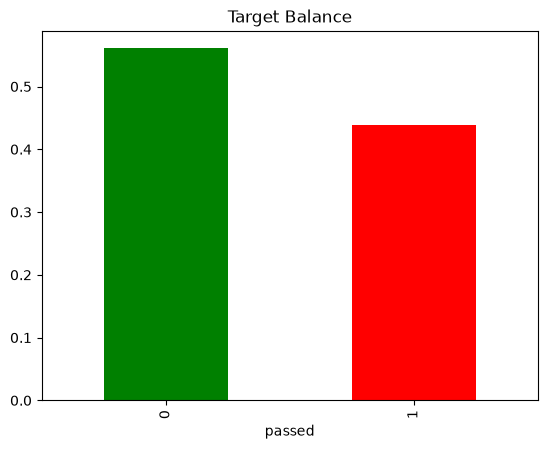

In [37]:
# check the dataframe is balanced or not
df["passed"].value_counts(normalize=True).plot(kind="bar", title="Target Balance", color=["green", "red"])

**Leakage decision.** `final_score` is only known *after* the exam, and it basically determines `passed`. Using it would give an unrealistically perfect model that is useless for predicting *before* the result. So:

- **y** = `passed`
- **X** = `hours_studied`, `attendance`, `practice_tests`, `sleep_hours` (numeric) and `study_method` (categorical)
- **Excluded:** `final_score` (leakage)

In [38]:
df.columns

Index(['hours_studied', 'attendance', 'practice_tests', 'sleep_hours',
       'study_method', 'final_score', 'passed'],
      dtype='str')

In [39]:
# separate features, target variables for better understanding of the data and for further processing
TARGET = "passed"
NUMERICAL = ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours']
CATEGORIAL = ["study_method"]
FEATURES = NUMERICAL + CATEGORIAL

# display the independent and dependent variables
X = df[FEATURES]
y = df[TARGET]
# 
assert "final_score" not in X.columns
print("Used Features:", FEATURES)
print("Target feature:", TARGET)

Used Features: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']
Target feature: passed


# 2. Split and baseline

In [40]:
# train and test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# 
print(f"Train: {X_train.shape} | Test: {X_test.shape}.")

Train: (224, 5) | Test: (56, 5).


In [49]:
# Train DummyClassifier as a simple baseline.
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print(f"Dummy accuracy: {round(accuracy_score(y_test, dummy_pred), 3)}")
print(f"F1 score      : {f1_score(y_test, dummy_pred, zero_division=0)}")

Dummy accuracy: 0.554
F1 score      : 0.0


The Dummy model always predicts the majority class (fail). Any real model must beat this to be useful. Its F1 is 0 because it never predicts a pass.

# 3. Train at least two candidate models

# 4. Evaluate fairly

# 5. Save and predict

# 6. Simple Streamlit interface